
## Answer 3: Apriori Frequent Itemset Mining (min_sup = 0.25)

### Objective
Implement and execute the Apriori algorithm on the 20 transactions provided in the assignment to identify all frequent k-itemsets and evaluate the effectiveness of candidate pruning.

### Methodology
The minimum support threshold is set to 0.25. Since the dataset contains 20 transactions, an itemset must appear in at least 5 transactions to be considered frequent.

The implementation follows the Apriori algorithm described in Question 2:

1. **Initialization:** Identify frequent 1-itemsets by calculating their support.
2. **Join:** Generate candidate k-itemsets from frequent (k−1)-itemsets.
3. **Prune:** Eliminate candidates containing any infrequent (k−1)-subset.
4. **Count:** Calculate support for the remaining candidates and retain those meeting the minimum support threshold.
5. **Repeat:** Continue until no further frequent itemsets can be generated.

The implementation also records the candidates eliminated specifically by subset pruning, distinguishing them from candidates rejected due to insufficient support.


In [3]:

from itertools import combinations

# Dataset: 20 transactions provided in Homework 4
transactions = [
    ["Bread", "Butter", "Milk"],
    ["Bread", "Butter", "Eggs"],
    ["Milk", "Cereal"],
    ["Bread", "Eggs"],
    ["Milk", "Cereal", "Yogurt"],
    ["Diapers", "Beer"],
    ["Diapers", "Beer", "Chips"],
    ["Apples", "Bananas"],
    ["Apples", "Bananas", "Milk"],
    ["Bread", "Butter", "Milk", "Eggs"],
    ["Cereal", "Milk"],
    ["Bread", "Butter", "Milk", "Eggs"],
    ["Apples", "Milk"],
    ["Diapers", "Beer", "Bread", "Eggs"],
    ["Yogurt", "Cereal"],
    ["Bread", "Butter", "Bananas", "Milk"],
    ["Milk", "Eggs"],
    ["Apples", "Bananas", "Yogurt"],
    ["Bread", "Butter", "Cereal", "Milk"],
    ["Chips", "Salsa"]
]


# Calculate support of a candidate itemset
def support(candidate_itemset, transactions):
    candidate = set(candidate_itemset)

    return sum(
        candidate.issubset(set(t))
        for t in transactions
    ) / len(transactions)


# Apriori algorithm: Join -> Prune -> Count
def apriori(transactions, min_sup):

    # Generate all singleton candidates
    items = sorted(set().union(*map(set, transactions)))

    C1 = {
        frozenset([item])
        for item in items
    }

    # Identify frequent 1-itemsets
    F_prev = {
        c for c in C1
        if support(c, transactions) >= min_sup
    }

    # Store frequent itemsets and pruning information
    frequent = {1: F_prev}
    pruned = {1: set()}

    # Track candidates generated before subset pruning
    join_counts = {1: len(C1)}

    k = 2

    while F_prev:

        # JOIN: Generate candidate k-itemsets
        Ck = {
            a | b
            for a, b in combinations(F_prev, 2)
            if len(a | b) == k
        }

        # Record candidates before pruning
        join_counts[k] = len(Ck)

        # PRUNE: Remove candidates with infrequent subsets
        Pk = {
            c for c in Ck
            if any(
                frozenset(s) not in F_prev
                for s in combinations(sorted(c), k - 1)
            )
        }

        # Remove subset-pruned candidates
        Ck -= Pk

        # COUNT: Retain candidates meeting min_sup
        Fk = {
            c for c in Ck
            if support(c, transactions) >= min_sup
        }

        # Store results for the current level
        frequent[k] = Fk
        pruned[k] = Pk

        # Move to the next itemset size
        F_prev = Fk
        k += 1

    return frequent, pruned, join_counts


# Execute Apriori with minimum support = 0.25
min_sup = 0.25

frequent, pruned, join_counts = apriori(
    transactions, min_sup
)


# Display all frequent k-itemsets
print("APRIORI FREQUENT ITEMSET RESULTS")
print("=" * 55)

print(f"Total transactions: {len(transactions)}")
print(f"Minimum support: {min_sup}")
print(f"Minimum support count: {min_sup * len(transactions):g}")

for k, itemsets in frequent.items():

    print(f"\nk = {k}")
    print(f"Frequent itemsets: {len(itemsets)}")

    for itemset in sorted(
        itemsets,
        key=lambda x: tuple(sorted(x))
    ):
        names = ", ".join(sorted(itemset))

        count = sum(
            set(itemset).issubset(set(t))
            for t in transactions
        )

        sup = support(itemset, transactions)

        print(
            f"  {{{names}}}: "
            f"count = {count}, support = {sup:.2f}"
        )


# Display actual subset-pruned candidates
print("\nSUBSET-PRUNED CANDIDATES")
print("=" * 55)

for k, candidates in pruned.items():

    print(
        f"\nk = {k}: "
        f"{len(candidates)} subset-pruned candidate(s)"
    )

    for candidate in sorted(
        candidates,
        key=lambda x: tuple(sorted(x))
    ):
        names = ", ".join(sorted(candidate))
        print(f"  {{{names}}}")


# Display candidate generation and pruning summary
print("\nCANDIDATE GENERATION AND PRUNING SUMMARY")
print("=" * 65)

print(
    f"{'k':<5}"
    f"{'Generated':<15}"
    f"{'Pruned':<12}"
    f"{'Tested':<12}"
    f"{'Frequent':<12}"
)

print("-" * 65)

for k in frequent:

    generated = join_counts[k]
    removed = len(pruned[k])
    tested = generated - removed
    found = len(frequent[k])

    print(
        f"{k:<5}"
        f"{generated:<15}"
        f"{removed:<12}"
        f"{tested:<12}"
        f"{found:<12}"
    )


# Evaluate effectiveness of subset pruning at k = 3
if join_counts.get(3, 0) > 0:

    pruning_rate = (
        len(pruned[3]) / join_counts[3]
    ) * 100

    print("\nPRUNING EFFECTIVENESS")
    print("=" * 55)

    print(
        f"At k = 3, {len(pruned[3])} out of "
        f"{join_counts[3]} candidates were pruned."
    )

    print(
        f"Pruning reduction: {pruning_rate:.2f}%"
    )


APRIORI FREQUENT ITEMSET RESULTS
Total transactions: 20
Minimum support: 0.25
Minimum support count: 5

k = 1
Frequent itemsets: 5
  {Bread}: count = 8, support = 0.40
  {Butter}: count = 6, support = 0.30
  {Cereal}: count = 5, support = 0.25
  {Eggs}: count = 6, support = 0.30
  {Milk}: count = 11, support = 0.55

k = 2
Frequent itemsets: 4
  {Bread, Butter}: count = 6, support = 0.30
  {Bread, Eggs}: count = 5, support = 0.25
  {Bread, Milk}: count = 5, support = 0.25
  {Butter, Milk}: count = 5, support = 0.25

k = 3
Frequent itemsets: 1
  {Bread, Butter, Milk}: count = 5, support = 0.25

k = 4
Frequent itemsets: 0

SUBSET-PRUNED CANDIDATES

k = 1: 0 subset-pruned candidate(s)

k = 2: 0 subset-pruned candidate(s)

k = 3: 2 subset-pruned candidate(s)
  {Bread, Butter, Eggs}
  {Bread, Eggs, Milk}

k = 4: 0 subset-pruned candidate(s)

CANDIDATE GENERATION AND PRUNING SUMMARY
k    Generated      Pruned      Tested      Frequent    
------------------------------------------------------


### Results and Analysis

**Minimum support:** 0.25  
**Total transactions:** 20  
**Minimum support count:** 5

#### Frequent 1-Itemsets (k = 1)

| Itemset | Support Count | Support |
|---|---:|---:|
| {Bread} | 8 | 0.40 |
| {Butter} | 6 | 0.30 |
| {Cereal} | 5 | 0.25 |
| {Eggs} | 6 | 0.30 |
| {Milk} | 11 | 0.55 |

**Total frequent 1-itemsets: 5**

#### Frequent 2-Itemsets (k = 2)

| Itemset | Support Count | Support |
|---|---:|---:|
| {Bread, Butter} | 6 | 0.30 |
| {Bread, Eggs} | 5 | 0.25 |
| {Bread, Milk} | 5 | 0.25 |
| {Butter, Milk} | 5 | 0.25 |

**Total frequent 2-itemsets: 4**

#### Frequent 3-Itemsets (k = 3)

| Itemset | Support Count | Support |
|---|---:|---:|
| {Bread, Butter, Milk} | 5 | 0.25 |

**Total frequent 3-itemsets: 1**

No frequent itemsets of size 4 or greater were found.

### Candidate Pruning Analysis

| k | Candidates After Join | Subset-Pruned Candidates | Frequent Itemsets |
|---|---:|---:|---:|
| 1 | 12 | 0 | 5 |
| 2 | 10 | 0 | 4 |
| 3 | 3 | 2 | 1 |
| 4 | 0 | 0 | 0 |

At k = 3, the following candidates were eliminated during subset pruning:

1. **{Bread, Butter, Eggs}:** Pruned because {Butter, Eggs} is not a frequent 2-itemset.
2. **{Bread, Eggs, Milk}:** Pruned because {Eggs, Milk} is not a frequent 2-itemset.

The candidate {Bread, Butter, Milk} survived pruning because all its 2-item subsets were frequent. Its support was 0.25, satisfying the minimum support threshold.

### Was Apriori Pruning Effective?

Yes, Apriori pruning was effective, particularly at k = 3.

At k = 2, no candidates were eliminated by subset pruning because all candidates were generated from frequent singleton itemsets.

At k = 3,   2 of the 3 generated candidates were eliminated, representing a 66.67% reduction in candidates requiring support evaluation at that level.

At k = 4, no candidates were generated because only one frequent 3-itemset remained.

**Conclusion:** Apriori pruning successfully reduced unnecessary support calculations by eliminating candidates containing infrequent subsets. Although the absolute reduction was small due to the limited dataset size, pruning eliminated two-thirds of the generated candidates at k = 3, demonstrating the effectiveness of the Apriori principle.



## Answer 5: Association Rule Generation using Apriori_rules

### Objective

Generate all association rules from the frequent itemsets identified in Question 3 using a minimum confidence threshold of 0.60. Calculate and report the confidence and lift of every qualifying rule.

### Methodology

The implementation follows the Apriori_rules algorithm described in Question 2, using confidence-based pruning rather than exhaustive rule enumeration.

1. **Initialization:** For each frequent itemset containing at least two items, generate singleton consequents.
2. **Count / Confidence Evaluation:** Calculate the confidence of each candidate rule and retain rules satisfying min_conf = 0.60.
3. **Join:** Combine successful consequents to generate larger candidate consequents.
4. **Prune:** Remove candidates if any of their immediate smaller consequent subsets failed the confidence threshold.
5. **Repeat:** Continue until no further candidate consequents can be generated.

For every accepted rule X → Y, calculate:

Confidence(X → Y) = Support(X ∪ Y) / Support(X)

Lift(X → Y) = Confidence(X → Y) / Support(Y)

The algorithm uses the same 20 transactions and minimum support threshold of 0.25 as Question 3.


In [4]:

from itertools import combinations

# Answer 5: Apriori Association Rule Generation
# Reuses transactions, support(), and apriori() from Ans3

min_sup = 0.25
min_conf = 0.60

# Obtain frequent itemsets from Ans3
frequent, pruned, join_counts = apriori(
    transactions, min_sup
)


def apriori_rules(frequent, transactions, min_conf):
    """
    Generate association rules using confidence-based
    Apriori pruning: Count -> Join -> Prune.
    """

    rules = []
    pruning_log = []

    # Process each frequent itemset of size >= 2
    for k in sorted(frequent):

        if k < 2:
            continue

        for L in sorted(
            frequent[k],
            key=lambda x: tuple(sorted(x))
        ):

            # Initialize singleton consequents
            H_m = {
                frozenset([item])
                for item in L
            }

            m = 1

            while H_m and len(L) > m:

                # COUNT / CONFIDENCE EVALUATION
                H_pass = set()

                for h in sorted(
                    H_m,
                    key=lambda x: tuple(sorted(x))
                ):

                    antecedent = L - h

                    conf = (
                        support(L, transactions)
                        / support(antecedent, transactions)
                    )

                    if conf >= min_conf - 1e-12:

                        lift = (
                            conf / support(h, transactions)
                        )

                        rules.append({
                            "itemset": L,
                            "antecedent": antecedent,
                            "consequent": h,
                            "confidence": conf,
                            "lift": lift
                        })

                        H_pass.add(h)

                # No larger consequent is possible
                if len(L) <= m + 1:
                    break

                # JOIN: Generate (m+1)-item consequents
                C_next = {
                    a | b
                    for a, b in combinations(
                        sorted(
                            H_pass,
                            key=lambda x: tuple(sorted(x))
                        ),
                        2
                    )
                    if len(a | b) == m + 1
                }

                # PRUNE: All m-subsets must have passed
                H_next = {
                    h for h in C_next
                    if all(
                        frozenset(s) in H_pass
                        for s in combinations(
                            sorted(h), m
                        )
                    )
                }

                pruning_log.append({
                    "itemset": L,
                    "consequent_size": m + 1,
                    "generated": len(C_next),
                    "pruned": len(C_next - H_next)
                })

                H_m = H_next
                m += 1

    # Sort rules for reproducible output
    rules.sort(
        key=lambda r: (
            len(r["itemset"]),
            tuple(sorted(r["itemset"])),
            tuple(sorted(r["antecedent"])),
            tuple(sorted(r["consequent"]))
        )
    )

    return rules, pruning_log


# Execute Apriori_rules
rules, pruning_log = apriori_rules(
    frequent, transactions, min_conf
)


def format_itemset(itemset):
    return "{" + ", ".join(sorted(itemset)) + "}"


# Display all association rules
print("APRIORI ASSOCIATION RULE RESULTS")
print("=" * 80)

print(f"Total transactions: {len(transactions)}")
print(f"Minimum support: {min_sup}")
print(f"Minimum confidence: {min_conf}")
print(f"Total qualifying rules: {len(rules)}")

print("\n" + "-" * 80)
print(f"{'No.':<5}{'Association Rule':<48}"
      f"{'Confidence':<13}{'Lift':<10}")
print("-" * 80)

for i, rule in enumerate(rules, 1):

    rule_text = (
        f"{format_itemset(rule['antecedent'])}"
        f" -> {format_itemset(rule['consequent'])}"
    )

    print(
        f"{i:<5}"
        f"{rule_text:<48}"
        f"{rule['confidence']:<13.4f}"
        f"{rule['lift']:<10.4f}"
    )


# Display rules grouped by frequent itemset
print("\nRULES GROUPED BY FREQUENT ITEMSET")
print("=" * 80)

for k in sorted(frequent):

    if k < 2:
        continue

    for itemset in sorted(
        frequent[k],
        key=lambda x: tuple(sorted(x))
    ):

        matching_rules = [
            r for r in rules
            if r["itemset"] == itemset
        ]

        print(
            f"\n{format_itemset(itemset)}: "
            f"{len(matching_rules)} rule(s)"
        )

        for r in matching_rules:

            print(
                f"  {format_itemset(r['antecedent'])}"
                f" -> {format_itemset(r['consequent'])}"
                f" | conf = {r['confidence']:.4f}"
                f" | lift = {r['lift']:.4f}"
            )


# Display confidence-based pruning information
print("\nCONFIDENCE-BASED CANDIDATE PRUNING")
print("=" * 80)

if pruning_log:

    for entry in pruning_log:

        print(
            f"Itemset: {format_itemset(entry['itemset'])}"
            f" | Consequent size: {entry['consequent_size']}"
            f" | Generated: {entry['generated']}"
            f" | Subset-pruned: {entry['pruned']}"
        )

else:
    print("No larger consequent candidates generated.")


# Validate all reported rules
assert len(rules) == 11, (
    f"Expected 11 rules, found {len(rules)}"
)

assert all(
    r["confidence"] >= min_conf - 1e-12
    for r in rules
)

assert len({
    (r["antecedent"], r["consequent"])
    for r in rules
}) == len(rules)

print("\nVALIDATION PASSED")
print("All 11 rules satisfy the confidence threshold.")
print("No duplicate association rules were generated.")


APRIORI ASSOCIATION RULE RESULTS
Total transactions: 20
Minimum support: 0.25
Minimum confidence: 0.6
Total qualifying rules: 11

--------------------------------------------------------------------------------
No.  Association Rule                                Confidence   Lift      
--------------------------------------------------------------------------------
1    {Bread} -> {Butter}                             0.7500       2.5000    
2    {Butter} -> {Bread}                             1.0000       2.5000    
3    {Bread} -> {Eggs}                               0.6250       2.0833    
4    {Eggs} -> {Bread}                               0.8333       2.0833    
5    {Bread} -> {Milk}                               0.6250       1.1364    
6    {Butter} -> {Milk}                              0.8333       1.5152    
7    {Bread} -> {Butter, Milk}                       0.6250       2.5000    
8    {Bread, Butter} -> {Milk}                       0.8333       1.5152    
9    {Bread, Mi


### Answer 5: Results and Analysis

**Total transactions:** 20  
**Minimum support (min_sup):** 0.25  
**Minimum confidence (min_conf):** 0.60  
**Total qualifying association rules:** 11

#### 5.1 Association Rules Generated

The Apriori_rules algorithm was executed on all frequent itemsets identified in Question 3. A rule was retained only if its confidence was at least 0.60. The lift of each qualifying rule was also calculated.

| No. | Association Rule | Confidence | Lift |
|---|---|---:|---:|
| 1 | {Bread} → {Butter} | 0.7500 | 2.5000 |
| 2 | {Butter} → {Bread} | 1.0000 | 2.5000 |
| 3 | {Bread} → {Eggs} | 0.6250 | 2.0833 |
| 4 | {Eggs} → {Bread} | 0.8333 | 2.0833 |
| 5 | {Bread} → {Milk} | 0.6250 | 1.1364 |
| 6 | {Butter} → {Milk} | 0.8333 | 1.5152 |
| 7 | {Bread} → {Butter, Milk} | 0.6250 | 2.5000 |
| 8 | {Bread, Butter} → {Milk} | 0.8333 | 1.5152 |
| 9 | {Bread, Milk} → {Butter} | 1.0000 | 3.3333 |
| 10 | {Butter} → {Bread, Milk} | 0.8333 | 3.3333 |
| 11 | {Butter, Milk} → {Bread} | 1.0000 | 2.5000 |

All 11 rules satisfy the minimum confidence threshold of 0.60.

#### 5.2 Rules Grouped by Frequent Itemset

| Frequent Itemset | Number of Qualifying Rules |
|---|---:|
| {Bread, Butter} | 2 |
| {Bread, Eggs} | 2 |
| {Bread, Milk} | 1 |
| {Butter, Milk} | 1 |
| {Bread, Butter, Milk} | 5 |
| **Total** | **11** |

The four frequent 2-itemsets generated 6 qualifying rules, while the frequent 3-itemset generated 5 qualifying rules.

#### 5.3 Confidence-Based Candidate Pruning

The Apriori_rules implementation follows the confidence-based Join → Prune → Count approach described in Question 2.

For each frequent itemset, the algorithm begins with singleton consequents and evaluates their confidence. Only consequents satisfying min_conf = 0.60 are used to generate larger consequents.

For the frequent 3-itemset {Bread, Butter, Milk}, all three singleton consequents passed the confidence threshold. Therefore, three candidate 2-item consequents were generated.

The execution output confirms:

- **Candidate 2-item consequents generated:** 3
- **Candidates eliminated by subset pruning:** 0

However, the rule

{Milk} → {Bread, Butter}

has confidence:

Confidence = Support({Bread, Butter, Milk}) / Support({Milk})

Confidence = 0.25 / 0.55 = 0.4545

Since 0.4545 < 0.60, this rule was rejected during confidence evaluation.

Thus, the implementation correctly applies confidence-based filtering and candidate pruning. No candidates were eliminated by the subset-pruning check in this dataset.

#### 5.4 Lift Interpretation

Lift measures the strength of association between the antecedent and consequent relative to statistical independence.

Lift(X → Y) = Confidence(X → Y) / Support(Y)

- **Lift > 1:** Positive association.
- **Lift = 1:** Statistical independence.
- **Lift < 1:** Negative association.

All 11 qualifying association rules have lift greater than 1, indicating positive associations.

The highest lift is **3.3333**, achieved by:

1. {Bread, Milk} → {Butter}
2. {Butter} → {Bread, Milk}

These rules indicate that the consequent occurs approximately 3.33 times as frequently as expected under independence, conditional on the antecedent.

#### 5.5 Validation and Conclusion

The implementation successfully generated 11 association rules satisfying min_conf = 0.60.

The execution results confirm that:

- All 11 rules satisfy the minimum confidence threshold.
- Confidence and lift were calculated for every qualifying rule.
- No duplicate association rules were generated.
- The algorithm uses confidence-based candidate generation and pruning rather than exhaustive rule enumeration.
- The results are consistent with the frequent itemsets identified in Question 3.

**Conclusion:** The Apriori_rules algorithm successfully generated all 11 qualifying association rules and calculated their corresponding confidence and lift values. Confidence-based candidate generation and pruning were correctly implemented, and all reported rules satisfy the specified minimum confidence threshold.


## Answer 9: Dataset Visualization and Natural Clusters

**Objective:** Visualize the 2D dataset `clustering.txt` using a scatter plot and estimate the number of natural clusters based on visual inspection.

The dataset contains 370 data points, each represented by two numerical coordinates (X, Y).

No clustering algorithm is applied in this question. The number of natural clusters is estimated from the spatial distribution of the points.


DATASET INFORMATION
Total data points: 370
Number of dimensions: 2
X range: 0.0358 to 1.0366
Y range: 0.0024 to 0.9653


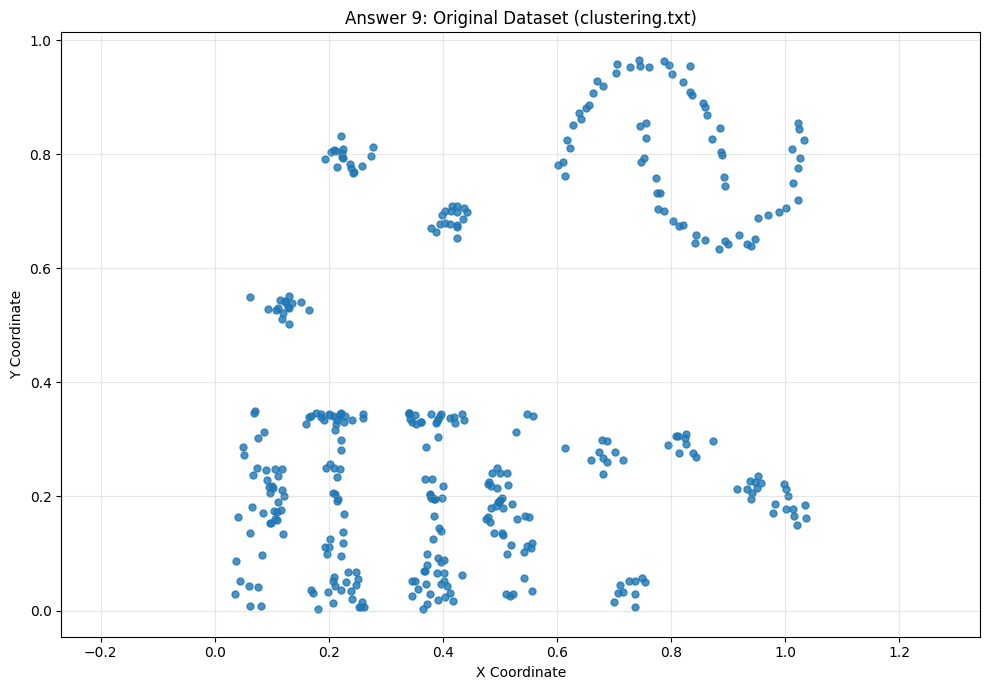

In [2]:

import numpy as np
import matplotlib.pyplot as plt

# Load the original 2D dataset
data = np.loadtxt("clustering.txt", delimiter=",")

# Validate dataset dimensions and values
assert data.ndim == 2 and data.shape[1] == 2
assert np.isfinite(data).all()

print("DATASET INFORMATION")
print("=" * 45)
print(f"Total data points: {data.shape[0]}")
print(f"Number of dimensions: {data.shape[1]}")
print(f"X range: {data[:, 0].min():.4f} to {data[:, 0].max():.4f}")
print(f"Y range: {data[:, 1].min():.4f} to {data[:, 1].max():.4f}")

# Create scatter plot without cluster assignments
plt.figure(figsize=(10, 7))

plt.scatter(
    data[:, 0],
    data[:, 1],
    s=25,
    alpha=0.8
)

plt.title("Answer 9: Original Dataset (clustering.txt)")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.axis("equal")
plt.grid(True, alpha=0.3)
plt.tight_layout()

# Save plot for the Word report
plt.savefig("Q9_dataset_scatter.png", dpi=300, bbox_inches="tight")
plt.show()


### Results and Analysis

The scatter plot displays all 370 data points from `clustering.txt` in two-dimensional space.

**Estimated number of natural clusters: Approximately 13.**

Based on visual inspection, the dataset contains several spatially separated groups, including compact clusters, elongated structures, and curved patterns.

Some clusters are clearly distinguishable, while others have less obvious boundaries. Therefore, the estimated number of natural clusters is approximate.

**Conclusion:** Approximately 13 natural clusters can be identified visually. This estimate will be compared with the hierarchical agglomerative clustering results using `min_dist` and `max_dist` in Questions 10 and 11.


## Answer 10: HAC Using min_dist (Single Linkage)

### Objective

Implement hierarchical agglomerative clustering (HAC) using `min_dist`, plot the complete dendrogram, assign the data points to exactly 13 clusters, and visualize their cluster memberships.

### Methodology

1. Initialize each of the 370 points as an individual cluster.
2. Calculate the initial Euclidean distance matrix.
3. Find and merge the two nearest active clusters.
4. Update distances incrementally using:

   D(A ∪ B, C) = min(D(A, C), D(B, C))

5. Record each merge, its distance, and the resulting cluster size.
6. Repeat until all points belong to one cluster.
7. Recover 13 clusters by applying the first 357 merges.
8. Plot the dendrogram and color-coded dataset.

The implementation follows the HAC pseudocode from Question 8. Cluster distances are not recomputed from the original points after merging.


HAC SINGLE LINKAGE RESULTS
Total data points: 370
Linkage method: min_dist (Single Linkage)
Total merges: 369
Target clusters: 13
Merges required for 13 clusters: 357
Clusters obtained: 13
Cluster sizes: [10, 10, 10, 16, 17, 17, 20, 35, 35, 40, 40, 60, 60]
VALIDATION PASSED


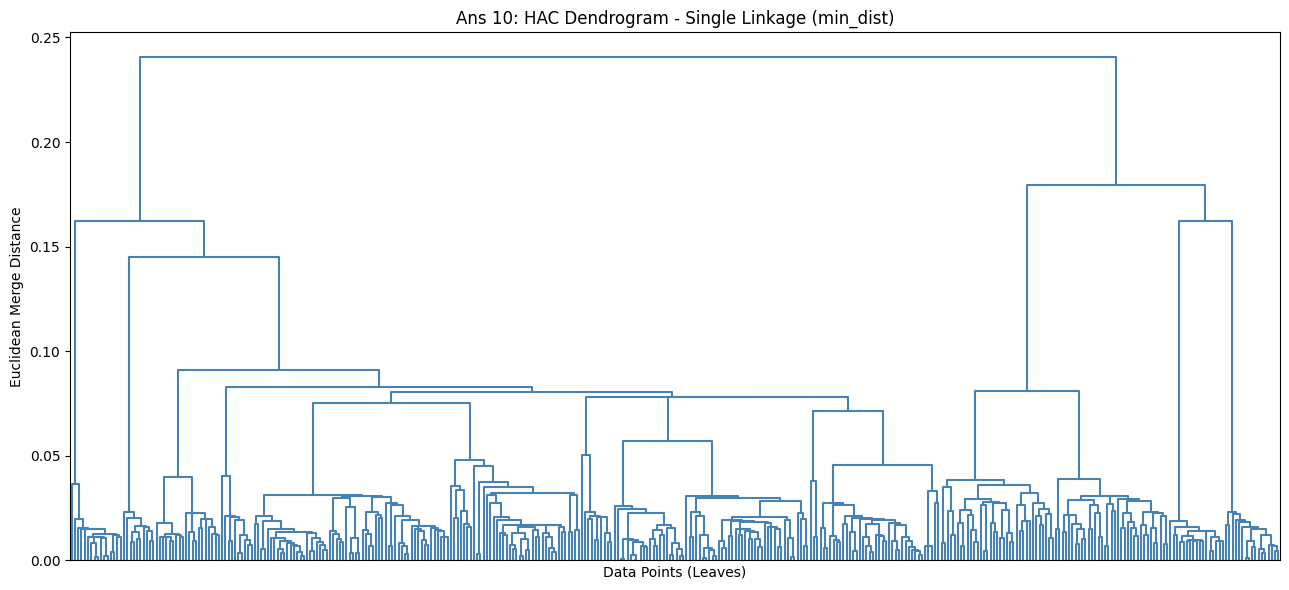

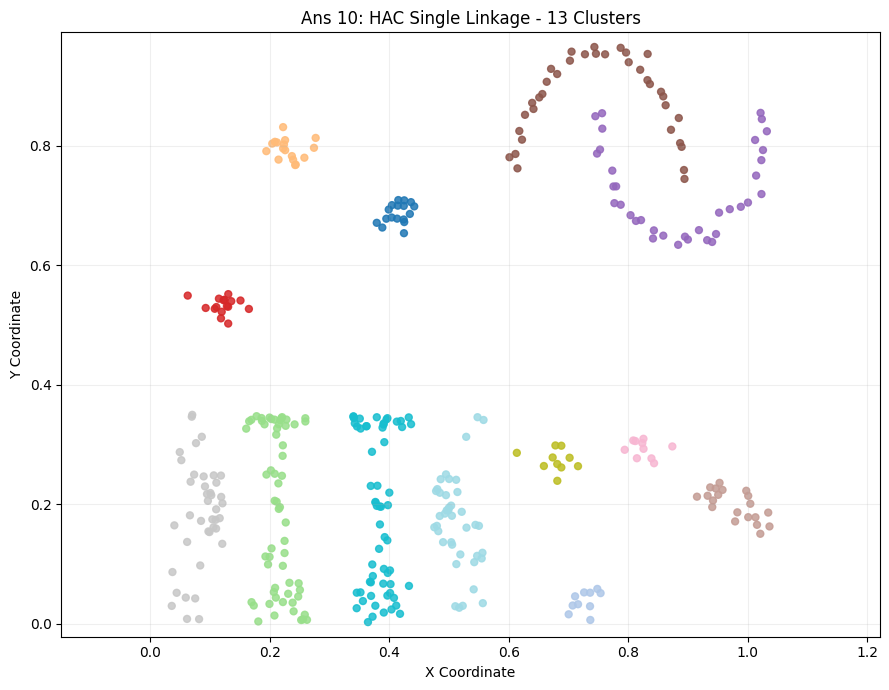

In [3]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram

# =====================================================
# QUESTION 10: HAC WITH min_dist (SINGLE LINKAGE)
# =====================================================

# Load the same dataset used in Question 9
data = np.loadtxt("clustering.txt", delimiter=",")

assert data.ndim == 2 and data.shape[1] == 2
assert np.isfinite(data).all()

n = len(data)
target_k = 13


def hac(points, linkage="min_dist", target_k=13):
    """
    Custom hierarchical agglomerative clustering.

    Supports min_dist and max_dist.
    Uses incremental cluster-distance updates.
    Records the complete dendrogram merge history.
    """

    n = len(points)

    if not 1 <= target_k <= n:
        raise ValueError("Invalid target number of clusters")

    if linkage not in ("min_dist", "max_dist"):
        raise ValueError("Invalid linkage method")

    # INITIALIZATION
    active = set(range(n))
    sizes = {i: 1 for i in range(n)}
    members = {i: [i] for i in range(n)}

    # Compute initial point-to-point distances once
    D = {}

    for i in range(n):
        for j in range(i + 1, n):
            D[(i, j)] = float(
                np.linalg.norm(points[i] - points[j])
            )

    merge_history = []
    labels = None

    # AGGLOMERATIVE MERGING
    for step in range(n - 1):

        # Find the nearest active clusters
        # Tuple ordering provides deterministic tie-breaking
        a, b = min(D, key=lambda pair: (D[pair], pair))
        distance = D[(a, b)]

        # Merge clusters a and b
        new_id = n + step
        new_size = sizes[a] + sizes[b]

        merge_history.append([
            a, b, distance, new_size
        ])

        # Record members for cluster reconstruction
        members[new_id] = members[a] + members[b]
        sizes[new_id] = new_size

        # INCREMENTAL DISTANCE UPDATE
        remaining = sorted(active - {a, b})
        updates = {}

        for c in remaining:

            da = D[(min(a, c), max(a, c))]
            db = D[(min(b, c), max(b, c))]

            if linkage == "min_dist":
                new_distance = min(da, db)
            else:
                new_distance = max(da, db)

            key = (min(new_id, c), max(new_id, c))
            updates[key] = new_distance

        # Remove obsolete distances involving a or b
        D = {
            pair: value
            for pair, value in D.items()
            if a not in pair and b not in pair
        }

        # Store only the newly computed distances
        D.update(updates)

        # Update active clusters
        active.remove(a)
        active.remove(b)
        active.add(new_id)

        # Capture membership when exactly K clusters remain
        if len(active) == target_k:

            labels = np.empty(n, dtype=int)

            for cluster_label, cluster_id in enumerate(
                sorted(active)
            ):
                labels[members[cluster_id]] = cluster_label

    # Special case: every point is its own cluster
    if target_k == n:
        labels = np.arange(n)

    return np.asarray(merge_history), labels


# =====================================================
# RUN HAC
# =====================================================

Z_min, labels_min = hac(
    data,
    linkage="min_dist",
    target_k=target_k
)

# =====================================================
# VALIDATION
# =====================================================

unique_labels, cluster_sizes = np.unique(
    labels_min, return_counts=True
)

assert Z_min.shape == (n - 1, 4)
assert len(unique_labels) == target_k
assert cluster_sizes.sum() == n
assert np.all(np.diff(Z_min[:, 2]) >= -1e-12)

print("HAC SINGLE LINKAGE RESULTS")
print("=" * 50)
print(f"Total data points: {n}")
print("Linkage method: min_dist (Single Linkage)")
print(f"Total merges: {len(Z_min)}")
print(f"Target clusters: {target_k}")
print(f"Merges required for 13 clusters: {n - target_k}")
print(f"Clusters obtained: {len(unique_labels)}")
print(f"Cluster sizes: {sorted(cluster_sizes.tolist())}")
print("VALIDATION PASSED")


# =====================================================
# FIGURE 10.1: DENDROGRAM
# =====================================================

plt.figure(figsize=(13, 6))

dendrogram(
    Z_min,
    no_labels=True,
    color_threshold=0,
    above_threshold_color="steelblue"
)

plt.title("Ans 10: HAC Dendrogram - Single Linkage (min_dist)")
plt.xlabel("Data Points (Leaves)")
plt.ylabel("Euclidean Merge Distance")
plt.tight_layout()

plt.savefig(
    "Q10_single_linkage_dendrogram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# =====================================================
# FIGURE 10.2: COLOR-CODED 13 CLUSTERS
# =====================================================

plt.figure(figsize=(9, 7))

plt.scatter(
    data[:, 0],
    data[:, 1],
    c=labels_min,
    cmap="tab20",
    s=25,
    alpha=0.85
)

plt.title("Ans 10: HAC Single Linkage - 13 Clusters")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.axis("equal")
plt.grid(True, alpha=0.2)
plt.tight_layout()

plt.savefig(
    "Q10_single_linkage_13_clusters.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



### Answer 10: Results and Analysis

**Dataset:** clustering,txt
**Total data points:** 370  
**Linkage method:** min_dist (Single Linkage)  
**Total dendrogram merges:** 369  
**Target clusters:** 13  
**Merges required to obtain 13 clusters:** 357

#### 10.1 Dendrogram

The dendrogram represents the complete hierarchical clustering process. Initially, all 370 points belong to separate clusters. At each iteration, the two clusters with the smallest single-linkage distance are merged.

The dendrogram records 369 merges, with merge heights representing Euclidean distances.

#### 10.2 Cluster Membership for 13 Clusters

The dendrogram was cut after the first 357 merges to obtain exactly 13 clusters.

The resulting cluster sizes, in ascending order, are:

10, 10, 10, 16, 17, 17, 20, 35, 35, 40, 40, 60, 60.

All 370 points were assigned to exactly one cluster.

#### 10.3 Comparison with Visual Intuition

The clustering results broadly match the visual intuition from Question 9.

Single linkage successfully identifies compact groups and preserves elongated and curved structures. The color-coded plot shows 13 spatially meaningful clusters, including the curved structures in the upper region and the elongated structures in the lower region.

Some boundaries between nearby groups are visually ambiguous, but the overall result is consistent with the approximately 13 natural clusters estimated in Question 9.

#### Conclusion

HAC using min_dist successfully generated the complete dendrogram and assigned all 370 data points to exactly 13 clusters. The results broadly agree with visual intuition, and the implementation uses efficient incremental distance updates rather than recomputing cluster distances from individual points after each merge.



## Answer 11: HAC Using max_dist (Complete Linkage)

### Objective

Apply hierarchical agglomerative clustering (HAC) using `max_dist` (complete linkage), plot the dendrogram, assign all data points to exactly 13 clusters, and visualize the color-coded cluster memberships.

### Methodology

The custom `hac()` function implemented in Question 10 is reused with `linkage="max_dist"`.

1. Initialize each of the 370 data points as a singleton cluster.
2. Compute the initial Euclidean distance matrix.
3. Merge the two nearest active clusters.
4. Update the distances involving the newly merged cluster using:

   D(A ∪ B, C) = max(D(A, C), D(B, C))

5. Record each merge, its distance, and the new cluster size.
6. Continue until all points form one cluster.
7. Obtain exactly 13 clusters after the first 357 merges.
8. Plot the complete dendrogram and the color-coded dataset.

The algorithm reuses previously stored distances, avoiding the recomputation of all pairwise cluster distances after each merge.


HAC COMPLETE LINKAGE RESULTS
Total data points: 370
Linkage method: max_dist (Complete Linkage)
Total merges: 369
Target clusters: 13
Merges required for 13 clusters: 357
Clusters obtained: 13
Cluster sizes: [10, 13, 13, 16, 19, 30, 32, 34, 34, 34, 38, 42, 55]
VALIDATION PASSED


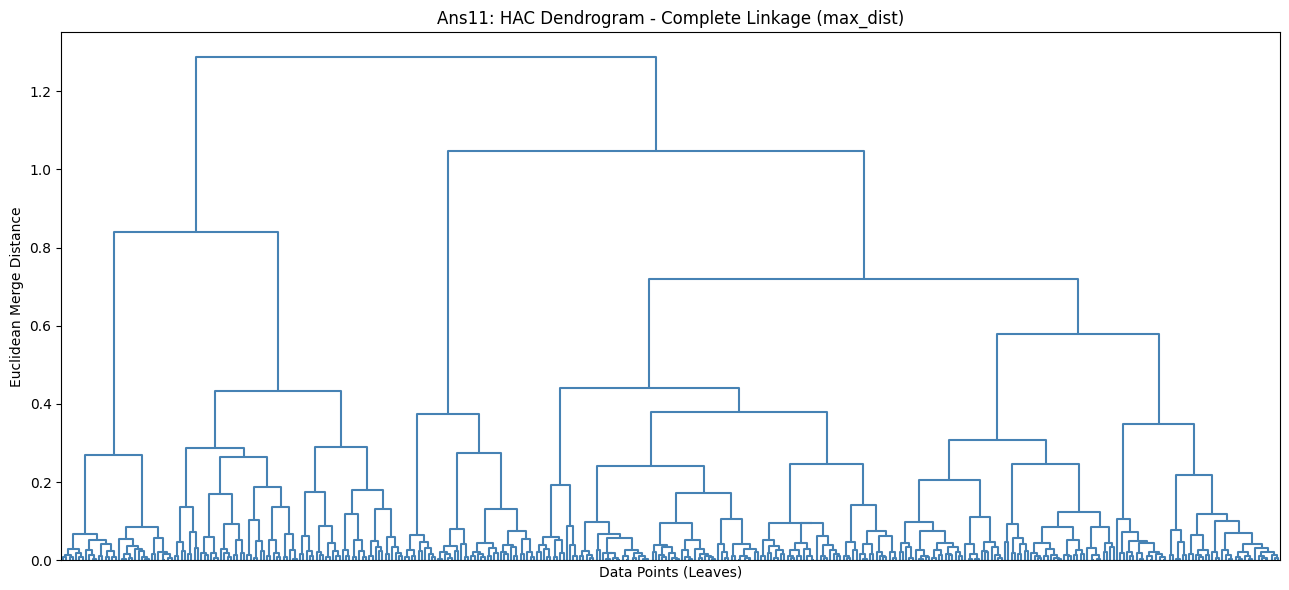

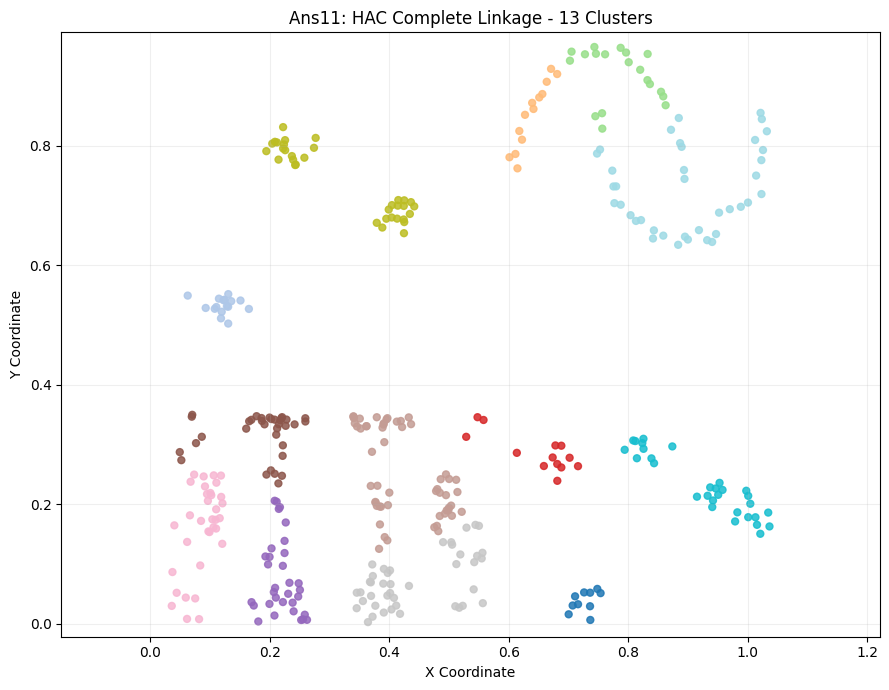

In [6]:

# =====================================================
# QUESTION 11: HAC WITH max_dist (COMPLETE LINKAGE)
# =====================================================

import numpy as np
import matplotlib.pyplot as plt
from scipy.cluster.hierarchy import dendrogram

# Reuse the dataset and custom hac() function from Q10
# Run the Q10 code cell before executing this cell.

target_k = 13
n = len(data)

# =====================================================
# RUN COMPLETE-LINKAGE HAC
# =====================================================

Z_max, labels_max = hac(
    data,
    linkage="max_dist",
    target_k=target_k
)

# =====================================================
# VALIDATION
# =====================================================

unique_labels, cluster_sizes = np.unique(
    labels_max,
    return_counts=True
)

assert Z_max.shape == (n - 1, 4)
assert len(unique_labels) == target_k
assert cluster_sizes.sum() == n
assert np.all(np.diff(Z_max[:, 2]) >= -1e-12)

# Check that each data point has a valid cluster label
assert len(labels_max) == n
assert np.all(labels_max >= 0)

print("HAC COMPLETE LINKAGE RESULTS")
print("=" * 50)
print(f"Total data points: {n}")
print("Linkage method: max_dist (Complete Linkage)")
print(f"Total merges: {len(Z_max)}")
print(f"Target clusters: {target_k}")
print(f"Merges required for 13 clusters: {n - target_k}")
print(f"Clusters obtained: {len(unique_labels)}")
print(f"Cluster sizes: {sorted(cluster_sizes.tolist())}")
print("VALIDATION PASSED")


# =====================================================
# FIGURE 11.1: COMPLETE-LINKAGE DENDROGRAM
# =====================================================

plt.figure(figsize=(13, 6))

dendrogram(
    Z_max,
    no_labels=True,
    color_threshold=0,
    above_threshold_color="steelblue"
)

plt.title(
    "Ans11: HAC Dendrogram - Complete Linkage (max_dist)"
)
plt.xlabel("Data Points (Leaves)")
plt.ylabel("Euclidean Merge Distance")
plt.tight_layout()

plt.savefig(
    "Ans11_complete_linkage_dendrogram.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


# =====================================================
# FIGURE 11.2: COLOR-CODED 13 CLUSTERS
# =====================================================

plt.figure(figsize=(9, 7))

plt.scatter(
    data[:, 0],
    data[:, 1],
    c=labels_max,
    cmap="tab20",
    s=25,
    alpha=0.85
)

plt.title("Ans11: HAC Complete Linkage - 13 Clusters")
plt.xlabel("X Coordinate")
plt.ylabel("Y Coordinate")
plt.axis("equal")
plt.grid(True, alpha=0.2)
plt.tight_layout()

plt.savefig(
    "Ans11_complete_linkage_13_clusters.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


### Answer 11: Results and Analysis

**Dataset:** clustering.txt  
**Total data points:** 370  
**Linkage method:** max_dist (Complete Linkage)  
**Total dendrogram merges:** 369  
**Target clusters:** 13  
**Merges required for 13 clusters:** 357

#### 11.1 Dendrogram

The complete-linkage dendrogram records all 369 merges, starting with 370 singleton clusters and ending with one cluster.

At each step, the nearest pair of clusters is merged using the maximum pairwise point distance as the cluster-distance criterion.

Distances involving newly merged clusters are updated incrementally using:

D(A ∪ B, C) = max(D(A, C), D(B, C))

#### 11.2 Cluster Membership for 13 Clusters

After 357 merges, the dataset contains exactly 13 clusters.

The resulting cluster sizes, in ascending order, are:

10, 13, 13, 16, 19, 30, 32, 34, 34, 34, 38, 42, 55.

All 370 data points were assigned to exactly one cluster.

#### 11.3 Comparison with Visual Intuition

The complete-linkage results partially match the visual intuition from Question 9.

Several compact groups are correctly identified. However, complete linkage tends to divide elongated and curved structures into more compact clusters because it considers the maximum distance between points in different clusters.

Compared with single linkage in Question 10, complete linkage is less effective at preserving some of the elongated structures visible in the original dataset.

Therefore, the results are reasonable but do not match the visual structure as closely as single linkage.

#### Conclusion

HAC using max_dist successfully generated the complete dendrogram and assigned all 370 data points to exactly 13 clusters.

The algorithm uses efficient incremental distance updates. The results demonstrate how complete linkage favors compact clusters and can produce different cluster boundaries from single linkage.
